# Heart disease

Inspect the UCI Heart Disease dataset (Cleveland, id 45). Each row is one patient. The features are clinical measurements, and `num` is the diagnosis: 0 means no disease, and 1 through 4 mean disease is present.

A logistic regression and a decision tree are the baseline on all five grades. The same patients are then used for disease versus no disease, and for the severity grade as an ordered score.

The disease model leaves out serum cholesterol and exercise-induced angina.


## Trust the dataset download

`ucimlrepo` checks the UCI server with the `certifi` certificate bundle. On this machine Avast Web/Mail Shield scans HTTPS, so the server certificate is issued by Avast's local root. Windows already trusts that root, and `certifi` does not. The next cell keeps certificate checks on and uses the Windows trust store for this session so the download can succeed.

In [1]:
import ssl

_create_default_context = ssl.create_default_context


def _create_default_context_windows_store(*args, **kwargs):
    '''Use the OS trust store, which includes the Avast scanning root.'''
    return _create_default_context()


ssl.create_default_context = _create_default_context_windows_store


## Load the dataset

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)

df = X.copy()
df["num"] = y.iloc[:, 0]


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

## Inspect the data

`df` is the 13 features plus the diagnosis column `num`. `ca` (number of major vessels) and `thal` are the only columns with missing values.

In [3]:
print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())


   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  
(303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       3

## Investigate the target

`num` is the angiographic diagnosis. Value 0 is absence of heart disease (164 patients). Values 1, 2, 3, and 4 mark presence, and the higher values are less common.

In [4]:
print(df["num"].value_counts().sort_index())


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


## Visualise relationships

The first plot is age against maximum heart rate (`thalach`), colored by the diagnosis. Patients with disease tend to sit toward a lower peak heart rate.

The pairplot crosses age, resting blood pressure (`trestbps`), cholesterol (`chol`), maximum heart rate (`thalach`), and ST depression (`oldpeak`).


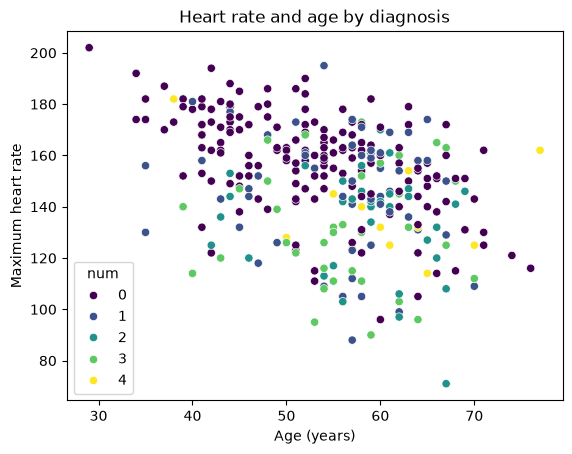

In [5]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(
    data=df,
    x="age",
    y="thalach",
    hue="num",
    palette="viridis",
)
plt.xlabel("Age (years)")
plt.ylabel("Maximum heart rate")
plt.title("Heart rate and age by diagnosis")
plt.show()


### Pairplot of the continuous measurements

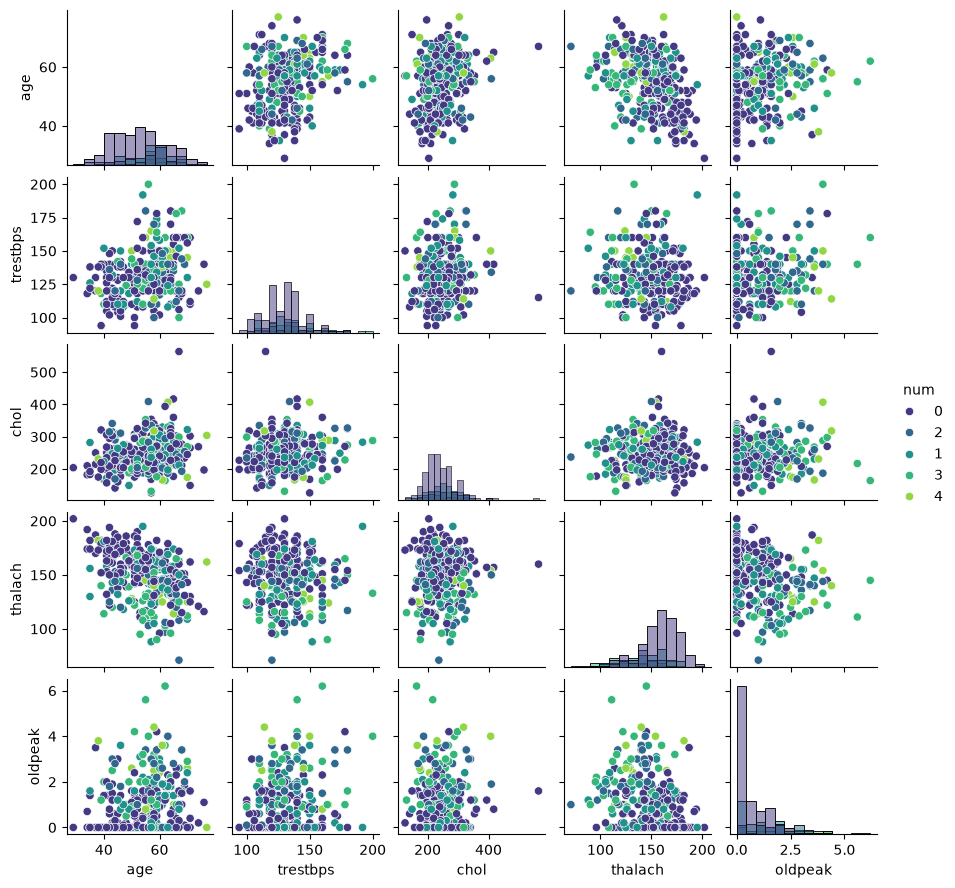

In [6]:
plot_df = df[["age", "trestbps", "chol", "thalach", "oldpeak"]].copy()
plot_df["num"] = df["num"].astype(str)

sns.pairplot(plot_df, hue="num", diag_kind="hist", height=1.8, palette="viridis")
plt.show()


## Train and test split

Hold out 20% of the patients. Stratify on `num` so each diagnosis level keeps the same share in both sets. Level 4 has only 13 patients, so the held-out set contains only a few of them.

In [7]:
from sklearn.model_selection import train_test_split

features = df.drop(columns="num")
labels = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())


Train: 242 Test: 61
num
0    131
1     44
2     29
3     28
4     10
Name: count, dtype: int64
num
0    33
1    11
2     7
3     7
4     3
Name: count, dtype: int64


## Logistic regression and a decision tree

`ca` is missing in 4 rows and `thal` in 2. A median imputer fills those gaps from the training rows only.

Logistic regression then scales every column. Age, blood pressure, cholesterol, and heart rate use different units, and a linear model is sensitive to that scale. The decision tree splits one column at a time, so it is not scaled. `random_state=42` keeps the tree reproducible.

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic regression": Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=10000)),
        ]
    ),
    "Decision tree": Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", DecisionTreeClassifier(random_state=42)),
        ]
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Fitted {name}")


Fitted Logistic regression
Fitted Decision tree


## Evaluate on the held-out set

Both models are scored on the same held-out patients. The confusion matrix is the stronger of the two.


Logistic regression
Accuracy: 0.607

              precision    recall  f1-score   support

           0       0.78      0.88      0.83        33
           1       0.36      0.36      0.36        11
           2       0.20      0.14      0.17         7
           3       0.43      0.43      0.43         7
           4       0.00      0.00      0.00         3

    accuracy                           0.61        61
   macro avg       0.36      0.36      0.36        61
weighted avg       0.56      0.61      0.58        61

Decision tree
Accuracy: 0.459

              precision    recall  f1-score   support

           0       0.75      0.73      0.74        33
           1       0.20      0.27      0.23        11
           2       0.17      0.14      0.15         7
           3       0.00      0.00      0.00         7
           4       0.00      0.00      0.00         3

    accuracy                           0.46        61
   macro avg       0.22      0.23      0.22        61
weighted 

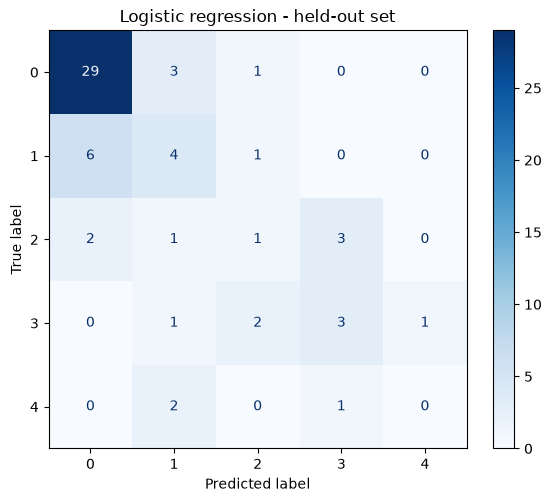

In [9]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)

scored = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    score = accuracy_score(y_test, y_pred)
    scored.append((score, name, model, y_pred))
    print(name)
    print(f"Accuracy: {score:.3f}")
    print()
    print(classification_report(y_test, y_pred))

_, best_name, best_model, best_pred = max(scored)
labels_order = list(best_model.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    labels=labels_order,
    ax=ax,
    cmap="Blues",
    xticks_rotation=0,
)
ax.set_title(f"{best_name} - held-out set")
fig.tight_layout()
plt.show()


## Disease or no disease

Grades 1 through 4 count as disease. Category codes (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`) are one-hot encoded. Six models are tuned on the training patients with stratified 5-fold cross-validation, scored by disease F1. The table ranks every model. The report and confusion matrix are for the top model.


In [10]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

y_train_disease = (y_train > 0).astype(int)
y_test_disease = (y_test > 0).astype(int)
y_train_severity = y_train.astype(int)
y_test_severity = y_test.astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def make_preprocess(scale):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))
    categorical = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", Pipeline(numeric_steps), numeric_features),
            ("categorical", categorical, categorical_features),
        ]
    )


def make_search(scale, estimator, param_grid, scoring):
    model = Pipeline(
        [
            ("preprocess", make_preprocess(scale)),
            ("model", estimator),
        ]
    )
    grid = {f"model__{name}": values for name, values in param_grid.items()}
    return GridSearchCV(
        model,
        grid,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    )


def chosen_settings(search):
    return {
        name.removeprefix("model__"): value
        for name, value in search.best_params_.items()
    }


def fit_searches(searches, y):
    for search in searches.values():
        search.fit(X_train, y)


def cross_validated_table(searches, metric):
    rows = []
    for name, search in searches.items():
        if metric == "disease F1":
            value = float(search.best_score_)
        else:
            value = float(-search.best_score_)
        rows.append({"model": name, metric: value})
    table = pd.DataFrame(rows)
    table = table.sort_values(metric, ascending=(metric != "disease F1"))
    return table.reset_index(drop=True)


print("Train disease cases:", int(y_train_disease.sum()), "of", len(y_train_disease))
print("Test disease cases:", int(y_test_disease.sum()), "of", len(y_test_disease))
print(y_train_severity.value_counts().sort_index())


Train disease cases: 111 of 242
Test disease cases: 28 of 61
num
0    131
1     44
2     29
3     28
4     10
Name: count, dtype: int64


In [11]:
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

binary_searches = {
    "Logistic regression": make_search(
        True,
        LogisticRegression(max_iter=10000, class_weight="balanced"),
        {"C": [0.01, 0.1, 1.0, 10.0]},
        "f1",
    ),
    "Decision tree": make_search(
        False,
        DecisionTreeClassifier(random_state=42, class_weight="balanced"),
        {"max_depth": [2, 3, 4, 5], "min_samples_leaf": [5, 8, 12]},
        "f1",
    ),
    "Random forest": make_search(
        False,
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
        ),
        {"max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 3, 5]},
        "f1",
    ),
    "Gradient boosting": make_search(
        False,
        HistGradientBoostingClassifier(random_state=42, class_weight="balanced"),
        {
            "learning_rate": [0.05, 0.1],
            "max_depth": [2, 3],
            "max_iter": [100, 200],
        },
        "f1",
    ),
    "RBF SVM": make_search(
        True,
        SVC(kernel="rbf", class_weight="balanced", random_state=42),
        {"C": [0.1, 1.0, 10.0], "gamma": ["scale", 0.1, 0.01]},
        "f1",
    ),
    "K-nearest neighbors": make_search(
        True,
        KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 7, 11, 15], "weights": ["uniform", "distance"]},
        "f1",
    ),
}

fit_searches(binary_searches, y_train_disease)
binary_table = cross_validated_table(binary_searches, "disease F1")
print(binary_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print()
print("Selected by cross-validated disease F1:", binary_table.iloc[0]["model"])


              model  disease F1
            RBF SVM       0.834
Logistic regression       0.834
K-nearest neighbors       0.821
      Random forest       0.807
  Gradient boosting       0.800
      Decision tree       0.780

Selected by cross-validated disease F1: RBF SVM


RBF SVM
Cross-validated disease F1: 0.834
Chosen settings: {'C': 10.0, 'gamma': 0.01}

              precision    recall  f1-score   support

  no disease       0.84      0.82      0.83        33
     disease       0.79      0.82      0.81        28

    accuracy                           0.82        61
   macro avg       0.82      0.82      0.82        61
weighted avg       0.82      0.82      0.82        61



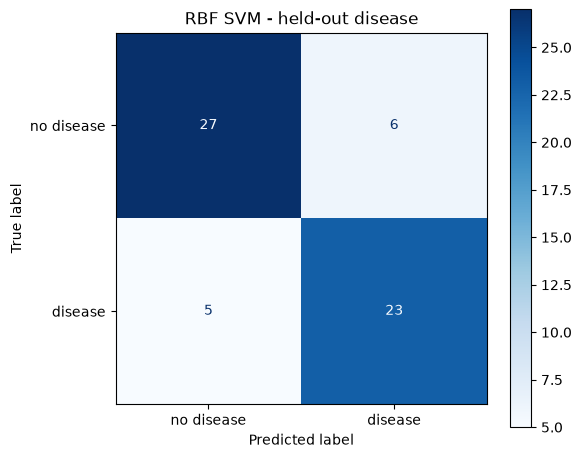

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_name = binary_table.iloc[0]["model"]
best_search = binary_searches[best_name]
y_pred = best_search.predict(X_test)
print(best_name)
print(f"Cross-validated disease F1: {best_search.best_score_:.3f}")
print(f"Chosen settings: {chosen_settings(best_search)}")
print()
print(classification_report(
    y_test_disease,
    y_pred,
    target_names=["no disease", "disease"],
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_disease,
    y_pred,
    display_labels=["no disease", "disease"],
    ax=ax,
    cmap="Blues",
    xticks_rotation=0,
)
ax.set_title(f"{best_name} - held-out disease")
fig.tight_layout()
plt.show()


## Without cholesterol or exercise angina

Serum cholesterol barely tracks disease in the training patients, so the disease model leaves `chol` out. Exercise-induced angina, `exang`, is left out with it. The other 11 measurements stay.

The support vector machine keeps the `C` and `gamma` chosen above.


Training correlation of chol with disease: 0.05
Left out: chol, exang
Settings: {'C': 10.0, 'gamma': 0.01}
Accuracy: 0.836
Disease F1: 0.833

              precision    recall  f1-score   support

  no disease       0.90      0.79      0.84        33
     disease       0.78      0.89      0.83        28

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61



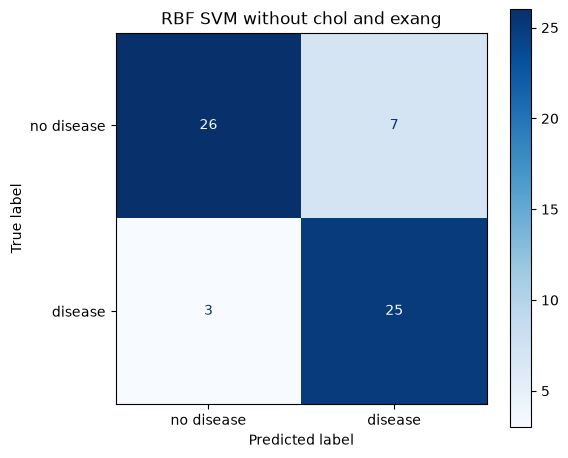

In [13]:
from sklearn.metrics import f1_score
from sklearn.svm import SVC


def preprocess_kept(numeric_cols, categorical_cols):
    categorical = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                list(numeric_cols),
            ),
            ("categorical", categorical, list(categorical_cols)),
        ]
    )


disease_numeric = [name for name in numeric_features if name != "chol"]
disease_categorical = [name for name in categorical_features if name != "exang"]
svm_settings = chosen_settings(binary_searches["RBF SVM"])
chol_correlation = X_train["chol"].corr((y_train > 0).astype(float))
print(f"Training correlation of chol with disease: {chol_correlation:.2f}")
print("Left out: chol, exang")
print("Settings:", svm_settings)

disease_model = Pipeline(
    [
        ("preprocess", preprocess_kept(disease_numeric, disease_categorical)),
        (
            "model",
            SVC(
                kernel="rbf",
                class_weight="balanced",
                random_state=42,
                C=svm_settings["C"],
                gamma=svm_settings["gamma"],
            ),
        ),
    ]
)
disease_model.fit(X_train, y_train_disease)
disease_pred = disease_model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test_disease, disease_pred):.3f}")
print(f"Disease F1: {f1_score(y_test_disease, disease_pred):.3f}")
print()
print(classification_report(
    y_test_disease,
    disease_pred,
    target_names=["no disease", "disease"],
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_disease,
    disease_pred,
    display_labels=["no disease", "disease"],
    ax=ax,
    cmap="Blues",
    xticks_rotation=0,
)
ax.set_title("RBF SVM without chol and exang")
fig.tight_layout()
plt.show()


## Ordered severity

The same model families predict the grade as a number from 0 to 4. Cross-validation keeps the lowest mean absolute error, then predictions are rounded to the nearest grade. The table ranks every model. The report and confusion matrix are for the top model.


In [14]:
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

ordinal_searches = {
    "Ridge": make_search(
        True,
        Ridge(),
        {"alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        "neg_mean_absolute_error",
    ),
    "Decision tree": make_search(
        False,
        DecisionTreeRegressor(random_state=42),
        {"max_depth": [2, 3, 4, 5], "min_samples_leaf": [5, 8, 12]},
        "neg_mean_absolute_error",
    ),
    "Random forest": make_search(
        False,
        RandomForestRegressor(n_estimators=200, random_state=42),
        {"max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 3, 5]},
        "neg_mean_absolute_error",
    ),
    "Gradient boosting": make_search(
        False,
        HistGradientBoostingRegressor(random_state=42),
        {
            "learning_rate": [0.05, 0.1],
            "max_depth": [2, 3],
            "max_iter": [100, 200],
        },
        "neg_mean_absolute_error",
    ),
    "RBF SVR": make_search(
        True,
        SVR(kernel="rbf"),
        {
            "C": [0.1, 1.0, 10.0],
            "gamma": ["scale", 0.1, 0.01],
            "epsilon": [0.1, 0.2],
        },
        "neg_mean_absolute_error",
    ),
    "K-nearest neighbors": make_search(
        True,
        KNeighborsRegressor(),
        {"n_neighbors": [3, 5, 7, 11, 15], "weights": ["uniform", "distance"]},
        "neg_mean_absolute_error",
    ),
}

fit_searches(ordinal_searches, y_train_severity)
ordinal_table = cross_validated_table(ordinal_searches, "mean absolute error")
print(ordinal_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print()
print(
    "Selected by cross-validated mean absolute error:",
    ordinal_table.iloc[0]["model"],
)


              model  mean absolute error
K-nearest neighbors                0.607
            RBF SVR                0.626
      Random forest                0.637
  Gradient boosting                0.640
              Ridge                0.645
      Decision tree                0.707

Selected by cross-validated mean absolute error: K-nearest neighbors


K-nearest neighbors
Cross-validated mean absolute error: 0.607
Chosen settings: {'n_neighbors': 7, 'weights': 'uniform'}
Held-out mean absolute error: 0.525
Exact grade: 0.607
Within one grade: 0.885


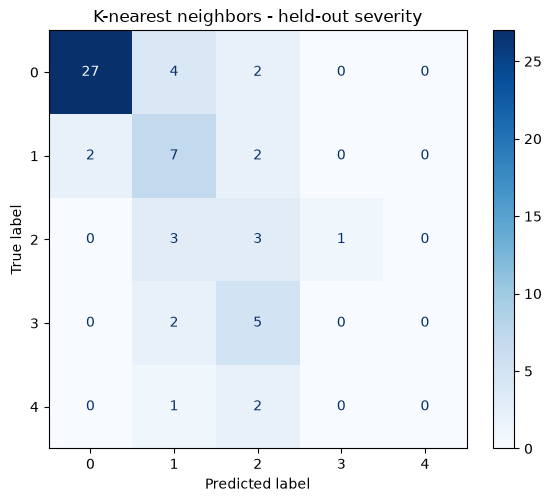

In [15]:
from sklearn.metrics import accuracy_score, mean_absolute_error


def grades_from_scores(scores):
    return np.clip(np.floor(np.asarray(scores, dtype=float) + 0.5), 0, 4).astype(int)


best_name = ordinal_table.iloc[0]["model"]
best_search = ordinal_searches[best_name]
raw_scores = best_search.predict(X_test)
grades = grades_from_scores(raw_scores)
truth = np.asarray(y_test_severity)
print(best_name)
print(f"Cross-validated mean absolute error: {-best_search.best_score_:.3f}")
print(f"Chosen settings: {chosen_settings(best_search)}")
print(f"Held-out mean absolute error: {mean_absolute_error(truth, grades):.3f}")
print(f"Exact grade: {accuracy_score(truth, grades):.3f}")
print(f"Within one grade: {np.mean(np.abs(truth - grades) <= 1):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_severity,
    grades,
    labels=[0, 1, 2, 3, 4],
    ax=ax,
    cmap="Blues",
    xticks_rotation=0,
)
ax.set_title(f"{best_name} - held-out severity")
fig.tight_layout()
plt.show()


## Conclusion

The data are 303 Cleveland patients, 13 clinical measurements, and a diagnosis `num` from 0 to 4. Sixty-one patients are held out.

Logistic regression and a decision tree are the baseline on all five grades. On the held-out patients, logistic regression reaches accuracy 0.607 and the tree reaches 0.459.

Grades 1 through 4 are then treated as disease. Six models are tuned on the training patients by disease F1. The selected model is an RBF support vector machine, with cross-validated disease F1 0.834. Serum cholesterol and exercise-induced angina are left out of that fit. On the held-out patients its accuracy is 0.836, and disease precision and recall are 0.78 and 0.89.

The same model families then predict the grade as a number from 0 to 4 and round it. K-nearest neighbors has the lowest cross-validated mean absolute error, 0.607. On the held-out patients the rounded grades have mean absolute error 0.525, exact-grade accuracy 0.607, and within one grade 0.885.

